In [ ]:
# 03 — Model Training (LightGBM)
Goal: Train LightGBM to predict temperature 15 minutes in the future, using time lags and power.

In [1]:
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the clean data
train = pd.read_csv("../data/processed/train_data.csv")
test = pd.read_csv("../data/processed/test_data.csv")

# Define Features (X) and Target (y)
# We drop 'time' (not useful for math) and 'temp' (current temp is cheating, 
# we only use past temp via lags) and 'temp_target_15m' (this is the answer!)
features = [
    'power_1', 'power_2', 'power_3', 
    'hour', 'minute', 'regime',
    'temp_lag_1m', 'temp_lag_5m', 'temp_lag_15m', 'temp_lag_60m',
    'power_1_lag_1m', 'power_1_lag_5m',
    'temp_rolling_mean_15m'
]
target = 'temp_target_15m'

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print(f"Training on {X_train.shape[0]} rows, Testing on {X_test.shape[0]} rows.")

Training on 16202 rows, Testing on 6579 rows.


In [2]:
# Initialize the LightGBM model
# We keep the parameters simple for now
model = lgb.LGBMRegressor(
    n_estimators=500,      # number of trees
    learning_rate=0.05,    # how fast it learns
    max_depth=7,           # how complex each tree is
    random_state=42        # for reproducibility
)

# Train the model
model.fit(X_train, y_train)
print("Model trained successfully!")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004223 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2634
[LightGBM] [Info] Number of data points in the train set: 16202, number of used features: 12
[LightGBM] [Info] Start training from score 23.529369
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [3]:
# Make predictions on the test set (the future!)
predictions = model.predict(X_test)

# Calculate the errors
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Mean Absolute Error (MAE): {mae:.3f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} °C")

# Baseline comparison: "Predict next = current"
# If our model isn't better than this, we failed.
baseline_mae = mean_absolute_error(y_test, test['temp'])
print(f"Baseline MAE (predict tomorrow = today): {baseline_mae:.3f} °C")

Mean Absolute Error (MAE): 0.490 °C
Root Mean Squared Error (RMSE): 0.621 °C
Baseline MAE (predict tomorrow = today): 0.820 °C


C:\Users\DELL\AppData\Local\Temp\ipykernel_18716\261399503.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance, palette='viridis')


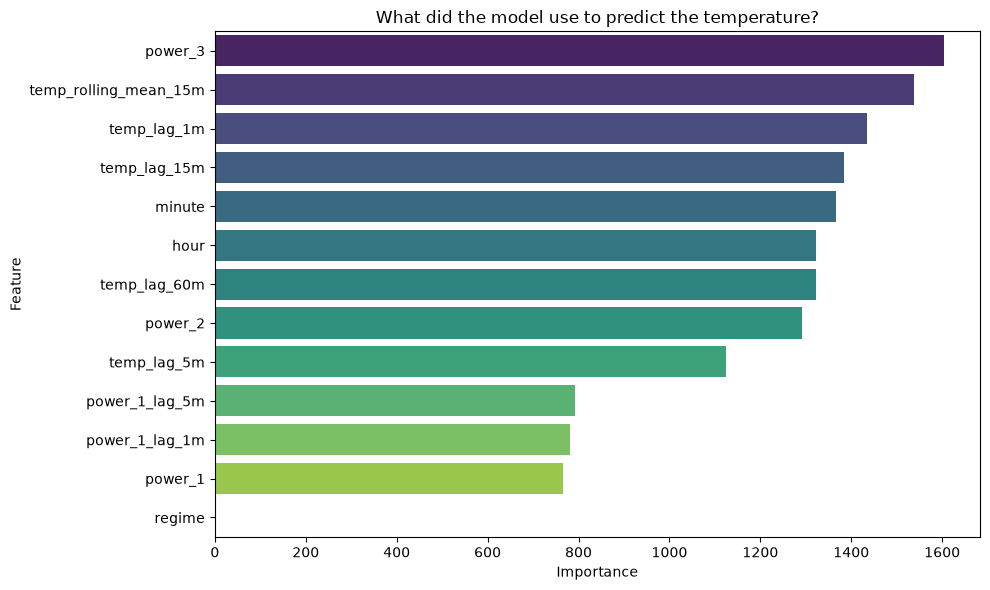

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance from the trained trees
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plot it
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance, palette='viridis')
plt.title('What did the model use to predict the temperature?')
plt.tight_layout()
plt.savefig('../reports/figures/04_feature_importance.png', dpi=150)
plt.show()